In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet

In [28]:
# NOTE: Global variables
WIDGET_SETTING = [
    "WIDGET_INDEX",
    "WIDGET_TITLE",
    "DATA_SOURCE",
    "DISPLAY_TYPE",
    "FILTERS",
    "START_DATE",
    "END_DATE",
    "FORECAST_LENGTH",  # only for forecast e.g."1Y" = 1 yr "1W" = 1 wk "1M" = 1 month
    "PROMOTION_WINDOWS",  # only for forecast this is a set data type
]

WIDGET_DISPLAY_TYPE = ["KPI",
                       "Forecast",
                       "Decomposition",
                       "Predicted Vs. Observed",
                       "Backtest Performance"]

WIDGET_COLUMN_COUNT = 2

FILTER_LIST = [
    "product_sku_code",
    "customer",
    "top_brand",
    "flavor_internal",
    "pack_type_internal",
    "pack_size_internal",
    "units_per_package_internal",
]


In [29]:
def load_data(filename: str):
    df = pd.DataFrame()
    if filename.endswith(".csv"):
        df = pd.read_csv(f"../data/{filename}")
    elif filename.endswith(".xlsx"):
        df = pd.read_excel(f"../data/{filename}")

    # ---------- process date ----------
    # print("---------- PROCESS DATE ----------")
    # print(df.tail())
    # print("---------- PROCESS DATE ----------")
    df["date"] = pd.to_datetime(
        df["yearweek"].astype(str) + "-1", format="%G%V-%u")
    df = df.sort_values("date", ascending=True)

    # ------------ clean data ------------
    all_dates = pd.DataFrame({"date": pd.date_range(
        start=df["date"].min(), end=df["date"].max(), freq="W-MON"
    )})
    all_products = pd.DataFrame(
        {"product_sku_code": df["product_sku_code"].unique()})

    cleaned_df = all_dates.merge(all_products, how="cross")

    complete_df = cleaned_df.merge(
        df, on=["date", "product_sku_code"], how="left")

    target_cols = complete_df.columns.difference(
        ["product_sku_code", "date", "nielsen_total_volume", "promotion_indicator"])

    lookup_table = df.drop_duplicates(
        "product_sku_code").set_index("product_sku_code")

    for col in target_cols:
        complete_df[col] = complete_df[col].fillna(
            complete_df["product_sku_code"].map(lookup_table[col]))
    complete_df["nielsen_total_volume"] = complete_df["nielsen_total_volume"].fillna(
        0)
    complete_df["promotion_indicator"] = complete_df["promotion_indicator"].fillna(
        0)

    print("--------------- COMPLETE DATA ---------------")
    print(complete_df.tail())
    # print(complete_df[["product_sku_code", "nielsen_total_volume"]].tail)
    print("--------------- COMPLETE DATA ---------------")

    return complete_df

def process_data(filename: str, filters: dict[str, str]):
    df = load_data(filename)
    # ---------- cumulate data ----------
    for key in FILTER_LIST:
        if filters[key] == "----- SELECT -----":
            continue

        match_value = filters[key]
        if key == "product_sku_code":
            match_value = int(match_value)
        df = df[df[key] == match_value]

    df = df.drop(columns=["product_sku_code"])
    df = df.groupby(by=["date"], as_index=False).sum()
    # print("||||||| PROCESS DATA |||||||")
    # print(df.tail())
    # print(df.columns)
    # print("||||||| PROCESS DATA |||||||")
    return df

def get_total_matches(filename: str, filters: dict[str, str]):
    df = load_data(filename)

    for key in FILTER_LIST:
        if filters[key] == "----- SELECT -----":
            continue

        match_value = filters[key]
        if key == "product_sku_code":
            match_value = int(match_value)
        df = df[df[key] == match_value]

    return len(df["product_sku_code"].unique())




In [30]:
def run_prophet_model(df: pd.DataFrame):

    model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        # seasonality_mode="multiplicative"
    )

    model.add_regressor("promotion_indicator")

    prophet_df = pd.DataFrame(
        {"ds": pd.to_datetime(df["date"]), "y": df["nielsen_total_volume"]}
    )

    prophet_df = pd.concat([prophet_df, df["promotion_indicator"]], axis=1)

    model.fit(prophet_df)

    # forecast['yhat'] = total prediction
    # forecast['yhat'] - forecast['promo'] = seasonality
    # forecast['promo'] = promotion

    print("&&&&&&&&&&&&&&&&&&&&& RUN PROPHET MODEL &&&&&&&&&&&&&&&&&&&&&")
    # print(forecast.columns)
    print("&&&&&&&&&&&&&&&&&&&&& RUN PROPHET MODEL &&&&&&&&&&&&&&&&&&&&&")
    return model, prophet_df


In [31]:
import os

folder_path = "../data"
if os.path.exists(folder_path):
    print(f"Files in '{folder_path}':", os.listdir(folder_path))
else:
    print(f"The folder '{folder_path}' was not found in {os.getcwd()}")

Files in '../data': ['dataGB.xlsx', 'raw', 'sample.xlsx', 'GB nielsen data with promo info 1.xlsx']


Canabalism will only run on individual product code basis 

In [32]:
df = load_data("dataGB.xlsx")

df.tail()
# for col in df.columns:
#     if col not in ["top_brand", "flavor_internal", "pack_type_internal", "pack_size_internal", "units_per_package_internal"]:
#         continue
#     print("-------------", col, "-------------")
#     print(df[col].unique())

--------------- COMPLETE DATA ---------------
             date  product_sku_code        customer    year  yearweek  \
188866 2025-10-20            644815         L2_CRTG  2025.0  202543.0   
188867 2025-10-20            644697        L2_TESCO  2025.0  202543.0   
188868 2025-10-20            644786        L2_TESCO  2025.0  202543.0   
188869 2025-10-20            644789  L2_SAINSBURY'S  2025.0  202543.0   
188870 2025-10-20            644789    L2_MORRISONS  2025.0  202543.0   

        nielsen_total_volume  promotion_indicator  \
188866                  86.0                  1.0   
188867                3924.0                  1.0   
188868                4037.0                  1.0   
188869                 498.0                  0.0   
188870                 580.0                  0.0   

                                   top_brand flavor_internal  \
188866  FANTA ZERO / NO SUGAR / DIET / LIGHT           BERRY   
188867           COCA-COLA LIGHT / DIET COKE   COLA & CHERRY   
1888

,date,product_sku_code,customer,year,yearweek,nielsen_total_volume,promotion_indicator,top_brand,flavor_internal,pack_type_internal,pack_size_internal,units_per_package_internal,material_medium_description
188866,2025-10-20,644815,L2_CRTG,2025.0,202543.0,86.0,1.0,FANTA ZERO / NO SUGAR / DIET / LIGHT,BERRY,PET,500ML,X1,500MLNRP X24 FTA ZRO FOREST BERRIES SRP
188867,2025-10-20,644697,L2_TESCO,2025.0,202543.0,3924.0,1.0,COCA-COLA LIGHT / DIET COKE,COLA & CHERRY,PET,2000ML,X1,2LNRP X6 DT CHRY COKE
188868,2025-10-20,644786,L2_TESCO,2025.0,202543.0,4037.0,1.0,FANTA ZERO / NO SUGAR / DIET / LIGHT,BERRY,CAN,330ML,X8,330MLCAN 3X8P FTA ZRO FOREST BERRIES
188869,2025-10-20,644789,L2_SAINSBURY'S,2025.0,202543.0,498.0,0.0,SCHWEPPES DIET,LEMON,CAN,330ML,X8,330MLCAN 3X8P SW SIMLNE LEM
188870,2025-10-20,644789,L2_MORRISONS,2025.0,202543.0,580.0,0.0,SCHWEPPES DIET,LEMON,CAN,330ML,X8,330MLCAN 3X8P SW SIMLNE LEM


In [33]:
for col in df.columns:
    if col not in ["top_brand", "flavor_internal", "pack_type_internal", "pack_size_internal", "units_per_package_internal"]:
        continue
    print("-------------", col, "-------------")
    print(df[col].unique())

------------- top_brand -------------
['MONSTER' 'COCA-COLA' 'SCHWEPPES' 'OASIS' 'COCA-COLA ZERO / NO SUGAR'
 'DR. PEPPER' 'COCA-COLA LIGHT / DIET COKE' 'FANTA' 'REIGN' 'RELENTLESS'
 'COSTA' 'SPRITE' 'SCHWEPPES DIET' 'SPRITE ZERO / NO SUGAR / DIET / LIGHT'
 'FANTA ZERO / NO SUGAR / DIET / LIGHT' 'APPLETISER' 'GLACEAU'
 'DR. PEPPER DIET' 'LILT DIET' 'POWERADE' 'LILT' 'DIET OASIS']
------------- flavor_internal -------------
['MANGO' 'COLA' 'LEMON' 'FRUIT' 'TONIC' 'COLA & VANILLA' 'NOT STATED'
 'ORANGE' 'PARADISE' 'COLA & CHERRY' 'WATERMELON' 'PEACH'
 'BROWNIE & CHOCOLATE' 'LEMON & LIME' 'CARAMEL' 'APPLE' 'PACIFIC PUNCH'
 'NOT FLAVOURED' 'RASPBERRY' 'GINGER' 'MELON' 'KHAOTIC' 'GRAPE'
 'GUAVA & ORANGE & PASSION FRUIT' 'SUPER DRY' 'GRAPEFRUIT & PINEAPPLE'
 'MIXXD' 'CITRUS' 'CHERRY' 'PASSION FRUIT' 'COLA & LIME' 'SODA'
 'BERRY & CARROT & HIBISCUS' 'BERRY' 'KIWI & STRAWBERRY' 'PINEAPPLE'
 'RIPPER' 'TONIC & ELDERFLOWER' 'TONIC & LEMON' 'TONIC & GRAPEFRUIT'
 'BERRY & FRUIT' 'GINGERBREAD' 'DRAG

In [ ]:
FLAVOR_MAPPING = {
    # COLAS
    'COLA': 'Cola',
    'COLA & VANILLA': 'Cola',
    'COLA & CHERRY': 'Cola',
    'COLA & LIME': 'Cola',
    'COLA & LEMON': 'Cola',
    'COLA & OREO': 'Cola',
    'COLA & CINNAMON': 'Cola',
    
    # CITRUS
    'LEMON': 'Citrus',
    'ORANGE': 'Citrus',
    'LEMON & LIME': 'Citrus',
    'CITRUS': 'Citrus',
    'GRAPEFRUIT': 'Citrus',
    'GRAPEFRUIT & PINEAPPLE': 'Citrus',
    'TONIC & LEMON': 'Citrus',
    'TONIC & GRAPEFRUIT': 'Citrus',
    'LEMON & RASPBERRY': 'Citrus',
    
    # TROPICAL & ENERGY PUNCH
    'MANGO': 'Tropical_Exotic',
    'PARADISE': 'Tropical_Exotic',
    'PACIFIC PUNCH': 'Tropical_Exotic',
    'GUAVA': 'Tropical_Exotic',
    'PINEAPPLE': 'Tropical_Exotic',
    'PASSION FRUIT': 'Tropical_Exotic',
    'DRAGONFRUIT': 'Tropical_Exotic',
    'GUAVA & ORANGE & PASSION FRUIT': 'Tropical_Exotic',
    'KHAOTIC': 'Tropical_Exotic',
    'PIPELINE PUNCH': 'Tropical_Exotic',
    'RIPPER': 'Tropical_Exotic',
    'MIXXD': 'Tropical_Exotic',
    'RIO PUNCH': 'Tropical_Exotic',
    'KIWI': 'Tropical_Exotic',
    'KIWI & STRAWBERRY': 'Tropical_Exotic',
    'WATERMELON': 'Tropical_Exotic',
    'MELON': 'Tropical_Exotic',
    'MELON & WATERMELON': 'Tropical_Exotic',
    'WATERLEMON': 'Tropical_Exotic', 
    
    # BERRIES & RED FRUITS
    'RASPBERRY': 'Berries_Red_Fruit',
    'BERRY': 'Berries_Red_Fruit',
    'STRAWBERRY': 'Berries_Red_Fruit',
    'CRANBERRY': 'Berries_Red_Fruit',
    'CHERRY': 'Berries_Red_Fruit',
    'APPLE': 'Berries_Red_Fruit',
    'APPLE & RASPBERRY': 'Berries_Red_Fruit',
    'APPLE & KIWI': 'Berries_Red_Fruit',
    'BERRY & FRUIT': 'Berries_Red_Fruit',
    'BERRY & CARROT & HIBISCUS': 'Berries_Red_Fruit',
    'ACAI & BLUEBERRY & POMEGRANATE': 'Berries_Red_Fruit',
    'BLUEBERRY & MOJITO': 'Berries_Red_Fruit',
    
    
    # TONICS & MIXERS
    'TONIC': 'Mixer',
    'TONIC & ELDERFLOWER': 'Mixer',
    'SODA': 'Mixer',
    'FRUIT & SODA': 'Mixer',
    'MOJITO': 'Mixer',
    'APERITIVO': 'Mixer',
    
    # DESSERT & INDULGENT
    'BROWNIE & CHOCOLATE': 'Indulgent',
    'CARAMEL': 'Indulgent',
    'VANILLA': 'Indulgent',
    'GINGERBREAD': 'Indulgent',
    'TIRAMISU': 'Indulgent',
    'OAT': 'Indulgent',
    'COCONUT & PEACH': 'Indulgent',
    
    # MISC / UNKNOWN
    'GINGER': 'Misc',
    'SUPER DRY': 'Misc',
    'NOT FLAVOURED': 'Misc',
    'NOT STATED': 'Misc',
    'ASSORTED': 'Misc'
}


BRAND_MAPPING = {
    # COLA - CORE
    'COCA-COLA': 'Cola_Regular',
    'DR. PEPPER': 'Cola_Regular',
    
    # COLA - DIET/ZERO
    'COCA-COLA ZERO / NO SUGAR': 'Cola_Diet_Zero',
    'COCA-COLA LIGHT / DIET COKE': 'Cola_Diet_Zero',
    'DR. PEPPER DIET': 'Cola_Diet_Zero',
    
    # ENERGY
    'MONSTER': 'Energy',
    'REIGN': 'Energy',
    'RELENTLESS': 'Energy',
    
    # FRUIT SODA & STILLS
    'FANTA': 'Fruit_Soda_Regular',
    'SPRITE': 'Fruit_Soda_Regular',
    'OASIS': 'Fruit_Soda_Regular',
    'LILT': 'Fruit_Soda_Regular',
    'APPLETISER': 'Fruit_Soda_Regular',
    
    # FRUIT SODA - DIET/ZERO
    'SPRITE ZERO / NO SUGAR / DIET / LIGHT': 'Fruit_Soda_Diet_Zero',
    'FANTA ZERO / NO SUGAR / DIET / LIGHT': 'Fruit_Soda_Diet_Zero',
    'LILT DIET': 'Fruit_Soda_Diet_Zero',
    'DIET OASIS': 'Fruit_Soda_Diet_Zero',
    
    # MIXERS
    'SCHWEPPES': 'Mixer',
    'SCHWEPPES DIET': 'Mixer',
    
    # SPECIALTY
    'COSTA': 'Misc',
    'POWERADE': 'Misc',
    'GLACEAU': 'Misc'
}

In [35]:
def classify_size(size_str):
    size = int("".join(filter(str.isdigit, size_str)))

    if size <= 375:
        return "S"
    elif size <= 850:
        return "M"
    elif size <= 1500:
        return "L"
    else:
        return "XL"
    
def classify_unit(unit_str):
    unit = int("".join(filter(str.isdigit, unit_str)))

    if unit <= 1:
        return "S"
    elif unit <= 9:
        return "M"
    elif unit <= 18:
        return "L"
    else:
        return "XL"
    
def classify_flavor(flavor_str):

    return FLAVOR_MAPPING.get(flavor_str, "Misc")

def classify_brand(brand_str):

    return BRAND_MAPPING.get(brand_str, "Misc")


In [36]:

MATCH_CAT = {
    "bfs": {"brand_cat", "flavor_cat", "size_cat"},
    "bfu": {"brand_cat", "flavor_cat", "unit_cat"},
    "bus": {"brand_cat", "unit_cat", "size_cat"},
    "fus": {"flavor_cat", "unit_cat", "size_cat"},
    "bfus": {"brand_cat", "flavor_cat", "unit_cat", "size_cat"}
}

In [64]:
def add_categories(df):
    df["brand_cat"] = df["top_brand"].apply(classify_brand)
    df["flavor_cat"] = df["flavor_internal"].apply(classify_flavor)
    df["size_cat"] = df["pack_size_internal"].apply(classify_size)
    df["unit_cat"] = df["units_per_package_internal"].apply(classify_unit)

    df.drop(columns=["top_brand",
                     "flavor_internal",
                     "pack_size_internal",
                     "units_per_package_internal"])
    return df



def process_categories(sku: int, df: pd.DataFrame):

    sku_row = df[df["product_sku_code"] == sku].iloc[0]

    results = {}

    sku_df = df[(df["product_sku_code"] == sku)].groupby("date", as_index=False).sum()
    sku_model, sku_prophet_df = run_prophet_model(sku_df)
    pred_sku = sku_model.predict(sku_prophet_df)
    pred_sku.index = pd.to_datetime(sku_prophet_df['ds'])

    actual_volume = sku_df.set_index("date")["nielsen_total_volume"]
    results["residual"] = pred_sku["yhat"] - actual_volume

    results["promotion_indicator"] = sku_df.set_index("date")["promotion_indicator"]

    for name, cols in MATCH_CAT.items():

        mask = pd.Series(True, index=df.index)
        for col in cols:
            mask &= (df[col] == sku_row[col])
        
        cat_weekly = df[mask].groupby("date")["nielsen_total_volume"].sum()
        others_weekly = df[mask & (df["product_sku_code"] != sku)].groupby("date")["nielsen_total_volume"].sum()
        current_share = (others_weekly / cat_weekly).fillna(0)
        #results[f"{name}_other_share_lag"] = current_share.shift(1)
        results[f"{name}_other_share_delta_lag"] = current_share.shift(1) - current_share.shift(2)

        group_df = df[mask].groupby("date", as_index=False).sum()
        group_model, group_prophet_df = run_prophet_model(group_df)
        pred_cat = group_model.predict(group_prophet_df)

        pred_cat.index = pd.to_datetime(group_prophet_df['ds'])

        pred_weekly = pred_cat["yhat"]
        pred_others_weekly = pred_cat["yhat"] - pred_sku["yhat"]
        pred_share = (pred_others_weekly / pred_weekly).fillna(0)

        #results[f"{name}_other_share_pred"] = pred_share
        results[f"{name}_other_share_delta_pred"] = pred_share - pred_share.shift(1)

    return pd.DataFrame(results)


In [78]:
df = load_data("dataGB.xlsx")

--------------- COMPLETE DATA ---------------
             date  product_sku_code        customer    year  yearweek  \
188866 2025-10-20            644815         L2_CRTG  2025.0  202543.0   
188867 2025-10-20            644697        L2_TESCO  2025.0  202543.0   
188868 2025-10-20            644786        L2_TESCO  2025.0  202543.0   
188869 2025-10-20            644789  L2_SAINSBURY'S  2025.0  202543.0   
188870 2025-10-20            644789    L2_MORRISONS  2025.0  202543.0   

        nielsen_total_volume  promotion_indicator  \
188866                  86.0                  1.0   
188867                3924.0                  1.0   
188868                4037.0                  1.0   
188869                 498.0                  0.0   
188870                 580.0                  0.0   

                                   top_brand flavor_internal  \
188866  FANTA ZERO / NO SUGAR / DIET / LIGHT           BERRY   
188867           COCA-COLA LIGHT / DIET COKE   COLA & CHERRY   
1888

In [229]:
sku = 279452 # coca cola, can, 330ml, x12
#sku = 407260
sku = 264471 # mango monster 4x
#sku = 406916 # fanta lemon 2000 ml
#sku = 414198 # fanta orange 2000ml 
new_df = df.copy()
new_df = add_categories(new_df)
new_df.tail()
processed_df = process_categories(sku, new_df)
processed_df.tail()

00:12:48 - cmdstanpy - INFO - Chain [1] start processing
00:12:49 - cmdstanpy - INFO - Chain [1] done processing
00:12:49 - cmdstanpy - INFO - Chain [1] start processing
00:12:49 - cmdstanpy - INFO - Chain [1] done processing
00:12:49 - cmdstanpy - INFO - Chain [1] start processing
00:12:49 - cmdstanpy - INFO - Chain [1] done processing
00:12:49 - cmdstanpy - INFO - Chain [1] start processing
00:12:49 - cmdstanpy - INFO - Chain [1] done processing


&&&&&&&&&&&&&&&&&&&&& RUN PROPHET MODEL &&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&& RUN PROPHET MODEL &&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&& RUN PROPHET MODEL &&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&& RUN PROPHET MODEL &&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&& RUN PROPHET MODEL &&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&& RUN PROPHET MODEL &&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&& RUN PROPHET MODEL &&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&& RUN PROPHET MODEL &&&&&&&&&&&&&&&&&&&&&


00:12:49 - cmdstanpy - INFO - Chain [1] start processing
00:12:49 - cmdstanpy - INFO - Chain [1] done processing
00:12:49 - cmdstanpy - INFO - Chain [1] start processing
00:12:49 - cmdstanpy - INFO - Chain [1] done processing


&&&&&&&&&&&&&&&&&&&&& RUN PROPHET MODEL &&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&& RUN PROPHET MODEL &&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&& RUN PROPHET MODEL &&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&& RUN PROPHET MODEL &&&&&&&&&&&&&&&&&&&&&


,residual,promotion_indicator,bfs_other_share_delta_lag,bfs_other_share_delta_pred,bfu_other_share_delta_lag,bfu_other_share_delta_pred,bus_other_share_delta_lag,bus_other_share_delta_pred,fus_other_share_delta_lag,fus_other_share_delta_pred,bfus_other_share_delta_lag,bfus_other_share_delta_pred
2025-09-22,-105.549121,5.0,-0.001403,-0.004651,0.004468,-0.012783,-0.002998,-0.002649,0.004468,-0.012783,0.004468,-0.012783
2025-09-29,-502.323860,5.0,-0.009616,0.004553,-0.017553,-0.005644,-0.003640,-0.001178,-0.017553,-0.005644,-0.017553,-0.005644
2025-10-06,-302.850722,4.0,-0.001004,0.007726,0.015573,0.006140,0.002227,0.000895,0.015573,0.006140,0.015573,0.006140
2025-10-13,1329.203828,3.0,0.049640,0.003517,-0.019458,0.006197,0.004281,0.001853,-0.019458,0.006197,-0.019458,0.006197
2025-10-20,1905.899756,2.0,0.012652,0.002665,0.019174,-0.003739,0.003625,0.003487,0.019174,-0.003739,0.019174,-0.003739


In [230]:
import lightgbm as lgb
features = [col for col in processed_df.columns]
features.remove("residual")

target = "residual"

processed_df.index.name = "date"
processed_df = processed_df.reset_index()
processed_df.tail()
split_date = processed_df["date"].max() - pd.Timedelta(weeks=15)

train = processed_df[processed_df["date"] < split_date]
test = processed_df[processed_df["date"] >= split_date]

X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]

train_data = lgb.Dataset(X_train, label=y_train)
test_data = lgb.Dataset(X_test, label=y_test, reference=train_data)

params = {
    "objective": "regression",
    "metric": "rmse",
    "learning_rate": 0.01,
    "max_depth": 7,         # Keep shallow to prevent overfitting
    "num_leaves": 120,
    "min_data_in_leaf": 10,
    "feature_fraction": 0.8, # Randomly select 80% of features per tree to find weak signals
    "verbose": -1
}

model = lgb.train(
    params,
    train_data,
    num_boost_round= 3000,
    valid_sets=[train_data, test_data],
    callbacks=[lgb.early_stopping(stopping_rounds=50)]
)

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[63]	training's rmse: 977.289	valid_1's rmse: 962.284


--- Evaluation Metrics ---
MAE:  811.19 units
RMSE: 962.28 units
MAPE: 149.62%


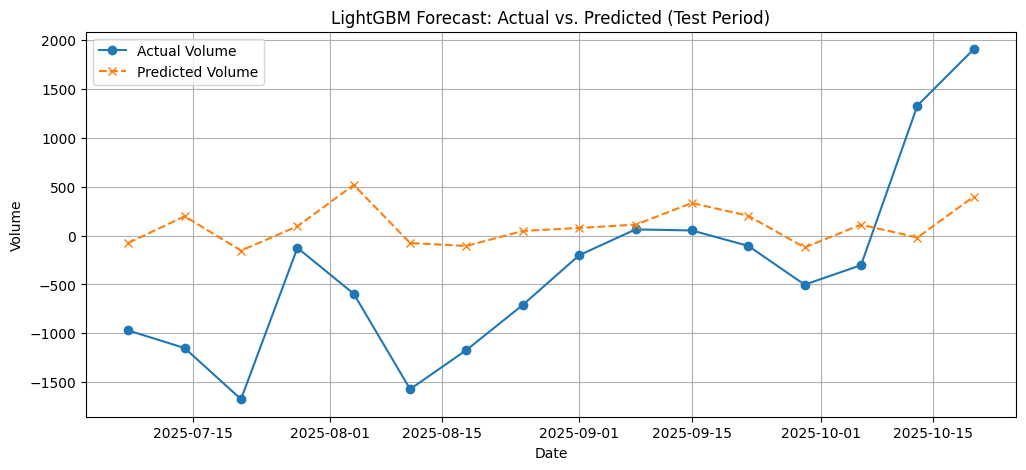

In [231]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
y_pred = model.predict(X_test)

# 2. Calculate Evaluation Metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Calculate MAPE (safely handling any zero-sales weeks)
mape = np.mean(np.abs((y_test - y_pred) / np.where(y_test == 0, 1e-10, y_test))) * 100

print(f"--- Evaluation Metrics ---")
print(f"MAE:  {mae:.2f} units")
print(f"RMSE: {rmse:.2f} units")
print(f"MAPE: {mape:.2f}%")

# 3. Visual Evaluation
plt.figure(figsize=(12, 5))
plt.plot(test["date"], y_test, label="Actual Volume", marker='o')
plt.plot(test["date"], y_pred, label="Predicted Volume", marker='x', linestyle="--")
plt.title("LightGBM Forecast: Actual vs. Predicted (Test Period)")
plt.xlabel("Date")
plt.ylabel("Volume")
plt.legend()
plt.grid(True)
plt.show()

In [232]:
# Calculate MPE, safely handling any zero-sales weeks
mpe = np.mean((y_test - y_pred) / np.where(y_test == 0, 1e-10, y_test)) * 100

print(f"MPE: {mpe:.2f}%")

MPE: 72.75%


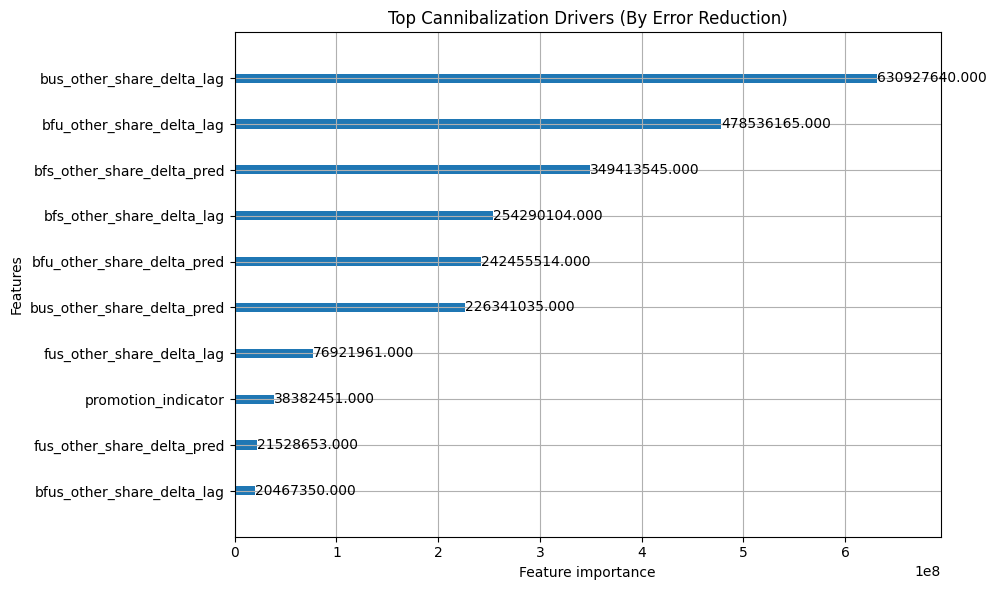

In [233]:
import matplotlib.pyplot as plt

# Plot which features drove the predictions
lgb.plot_importance(
    model, 
    importance_type='gain', 
    figsize=(10, 6), 
    title="Top Cannibalization Drivers (By Error Reduction)",
    max_num_features=10 # Show top 10
)
plt.tight_layout()
plt.show()